In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    classification_report, confusion_matrix, 
    precision_recall_curve, average_precision_score,
    roc_auc_score, f1_score
)
import warnings
warnings.filterwarnings('ignore')

pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', '{:.2f}'.format)

print("Libraries loaded successfully")

Libraries loaded successfully


In [2]:
# Load a sample first (recommended for first run)
# Change nrows=None when you want the full dataset
df = pd.read_csv("../data/raw/Paysim_dataset.csv", nrows=500_000)

print(f"Shape: {df.shape}")
print(f"Memory usage: {df.memory_usage(deep=True).sum() / 1024**2:.1f} MB")
df.head()

Shape: (500000, 11)
Memory usage: 55.5 MB


,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
0,1,PAYMENT,9839.64,C1231006815,170136.00,160296.36,M1979787155,0.00,0.00,0,0
1,1,PAYMENT,1864.28,C1666544295,21249.00,19384.72,M2044282225,0.00,0.00,0,0
2,1,TRANSFER,181.00,C1305486145,181.00,0.00,C553264065,0.00,0.00,1,0
3,1,CASH_OUT,181.00,C840083671,181.00,0.00,C38997010,21182.00,0.00,1,0
4,1,PAYMENT,11668.14,C2048537720,41554.00,29885.86,M1230701703,0.00,0.00,0,0


In [3]:
print("=== Column Info ===")
print(df.info())

print("\n=== Missing Values ===")
print(df.isnull().sum())

print("\n=== Fraud Distribution ===")
print(df['isFraud'].value_counts(normalize=True) * 100)

print("\n=== Transaction Types ===")
print(df['type'].value_counts())

=== Column Info ===
<class 'pandas.DataFrame'>
RangeIndex: 500000 entries, 0 to 499999
Data columns (total 11 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   step            500000 non-null  int64  
 1   type            500000 non-null  str    
 2   amount          500000 non-null  float64
 3   nameOrig        500000 non-null  str    
 4   oldbalanceOrg   500000 non-null  float64
 5   newbalanceOrig  500000 non-null  float64
 6   nameDest        500000 non-null  str    
 7   oldbalanceDest  500000 non-null  float64
 8   newbalanceDest  500000 non-null  float64
 9   isFraud         500000 non-null  int64  
 10  isFlaggedFraud  500000 non-null  int64  
dtypes: float64(5), int64(3), str(3)
memory usage: 55.5 MB
None

=== Missing Values ===
step              0
type              0
amount            0
nameOrig          0
oldbalanceOrg     0
newbalanceOrig    0
nameDest          0
oldbalanceDest    0
newbalanceDest    0
isFraud       

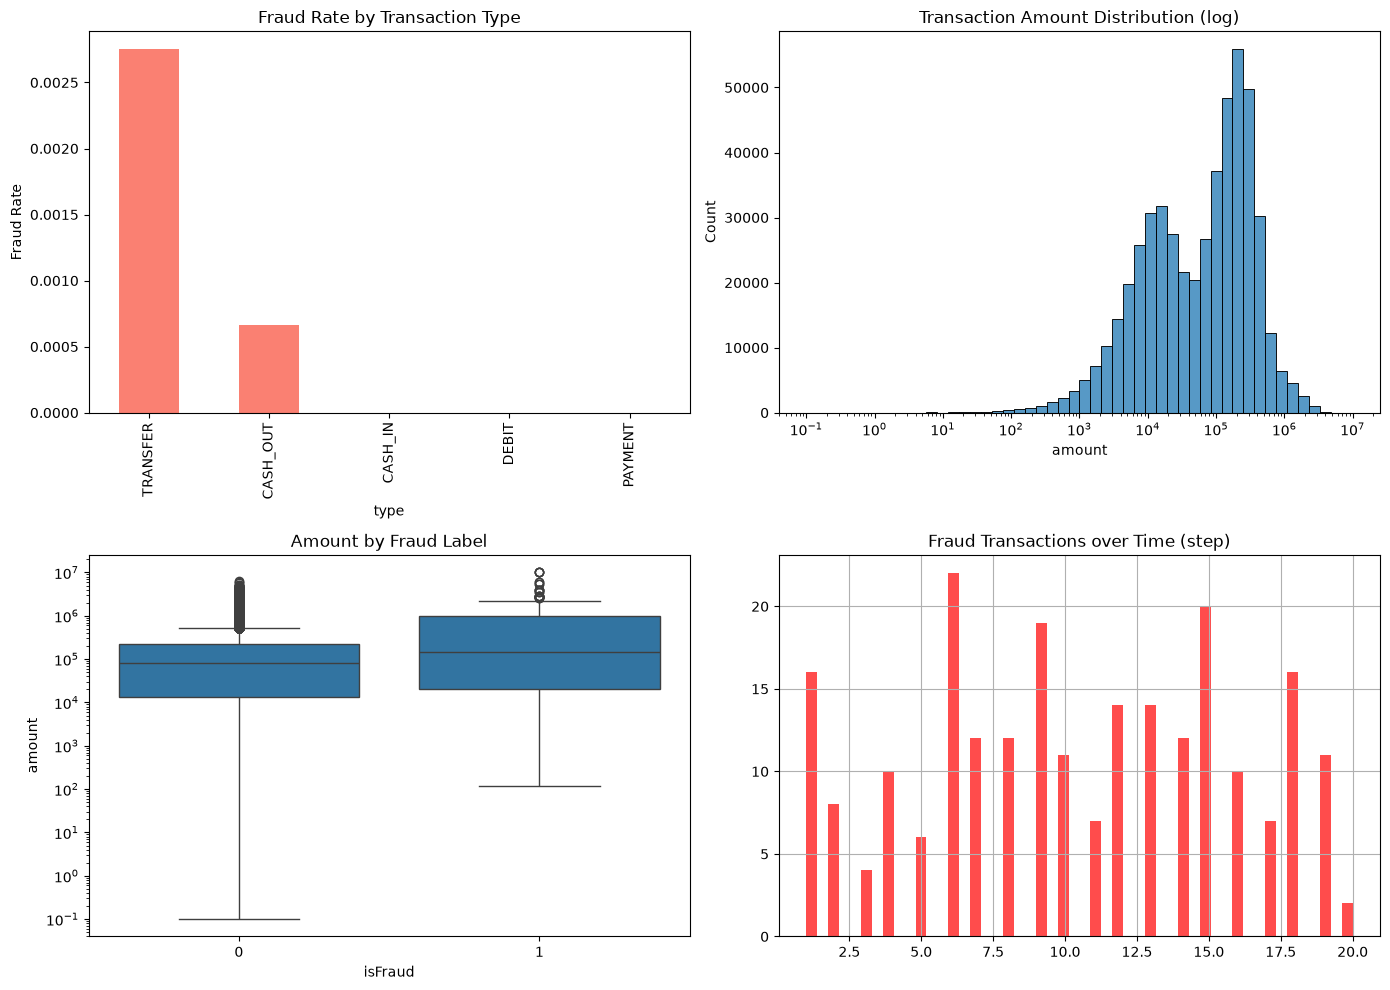

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Fraud rate by type
fraud_by_type = df.groupby('type')['isFraud'].mean().sort_values(ascending=False)
fraud_by_type.plot(kind='bar', ax=axes[0,0], color='salmon')
axes[0,0].set_title('Fraud Rate by Transaction Type')
axes[0,0].set_ylabel('Fraud Rate')

# Amount distribution (log scale)
sns.histplot(df['amount'], bins=50, log_scale=True, ax=axes[0,1])
axes[0,1].set_title('Transaction Amount Distribution (log)')

# Fraud vs Non-Fraud amount
sns.boxplot(data=df, x='isFraud', y='amount', ax=axes[1,0])
axes[1,0].set_yscale('log')
axes[1,0].set_title('Amount by Fraud Label')

# Step (time) distribution of fraud
df[df['isFraud']==1]['step'].hist(bins=50, ax=axes[1,1], color='red', alpha=0.7)
axes[1,1].set_title('Fraud Transactions over Time (step)')

plt.tight_layout()
plt.show()

In [5]:
def create_features(df):
    df = df.copy()
    
    # Balance change features
    df['orig_balance_diff'] = df['newbalanceOrig'] - df['oldbalanceOrg']
    df['dest_balance_diff'] = df['newbalanceDest'] - df['oldbalanceDest']
    
    # Error features (common in PaySim)
    df['orig_error'] = (df['oldbalanceOrg'] - df['amount'] - df['newbalanceOrig']).abs()
    df['dest_error'] = (df['oldbalanceDest'] + df['amount'] - df['newbalanceDest']).abs()
    
    # Binary flags
    df['is_orig_balance_zero'] = (df['oldbalanceOrg'] == 0).astype(int)
    df['is_dest_balance_zero'] = (df['oldbalanceDest'] == 0).astype(int)
    
    # Amount log
    df['log_amount'] = np.log1p(df['amount'])
    
    return df

df_feat = create_features(df)
print("Features created")
df_feat[['amount', 'orig_balance_diff', 'dest_balance_diff', 'orig_error', 'isFraud']].head()

Features created


,amount,orig_balance_diff,dest_balance_diff,orig_error,isFraud
0,9839.64,-9839.64,0.00,0.00,0
1,1864.28,-1864.28,0.00,0.00,0
2,181.00,-181.00,0.00,0.00,1
3,181.00,-181.00,-21182.00,0.00,1
4,11668.14,-11668.14,0.00,0.00,0


In [6]:
# Select features
feature_cols = [
    'amount', 'log_amount',
    'oldbalanceOrg', 'newbalanceOrig', 'orig_balance_diff', 'orig_error',
    'oldbalanceDest', 'newbalanceDest', 'dest_balance_diff', 'dest_error',
    'is_orig_balance_zero', 'is_dest_balance_zero'
]

# Encode transaction type
le = LabelEncoder()
df_feat['type_encoded'] = le.fit_transform(df_feat['type'])
feature_cols.append('type_encoded')

X = df_feat[feature_cols]
y = df_feat['isFraud']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"Train shape: {X_train.shape}")
print(f"Test shape:  {X_test.shape}")
print(f"Fraud rate in train: {y_train.mean()*100:.3f}%")

Train shape: (400000, 13)
Test shape:  (100000, 13)
Fraud rate in train: 0.046%


In [7]:
# Logistic Regression
lr = LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42)
lr.fit(X_train, y_train)
y_pred_lr = lr.predict(X_test)
y_prob_lr = lr.predict_proba(X_test)[:, 1]

print("=== Logistic Regression ===")
print(classification_report(y_test, y_pred_lr, digits=4))
print(f"PR-AUC: {average_precision_score(y_test, y_prob_lr):.4f}")
print(f"ROC-AUC: {roc_auc_score(y_test, y_prob_lr):.4f}")

# Random Forest (stronger baseline)
rf = RandomForestClassifier(
    n_estimators=100, 
    max_depth=12, 
    class_weight='balanced', 
    random_state=42, 
    n_jobs=-1
)
rf.fit(X_train, y_train)
y_pred_rf = rf.predict(X_test)
y_prob_rf = rf.predict_proba(X_test)[:, 1]

print("\n=== Random Forest ===")
print(classification_report(y_test, y_pred_rf, digits=4))
print(f"PR-AUC: {average_precision_score(y_test, y_prob_rf):.4f}")
print(f"ROC-AUC: {roc_auc_score(y_test, y_prob_rf):.4f}")

=== Logistic Regression ===
              precision    recall  f1-score   support

           0     0.9998    0.8323    0.9084     99953
           1     0.0019    0.6809    0.0038        47

    accuracy                         0.8322    100000
   macro avg     0.5009    0.7566    0.4561    100000
weighted avg     0.9994    0.8322    0.9080    100000

PR-AUC: 0.2427
ROC-AUC: 0.8761

=== Random Forest ===
              precision    recall  f1-score   support

           0     0.9999    1.0000    1.0000     99953
           1     1.0000    0.8723    0.9318        47

    accuracy                         0.9999    100000
   macro avg     1.0000    0.9362    0.9659    100000
weighted avg     0.9999    0.9999    0.9999    100000

PR-AUC: 0.8935
ROC-AUC: 0.9681


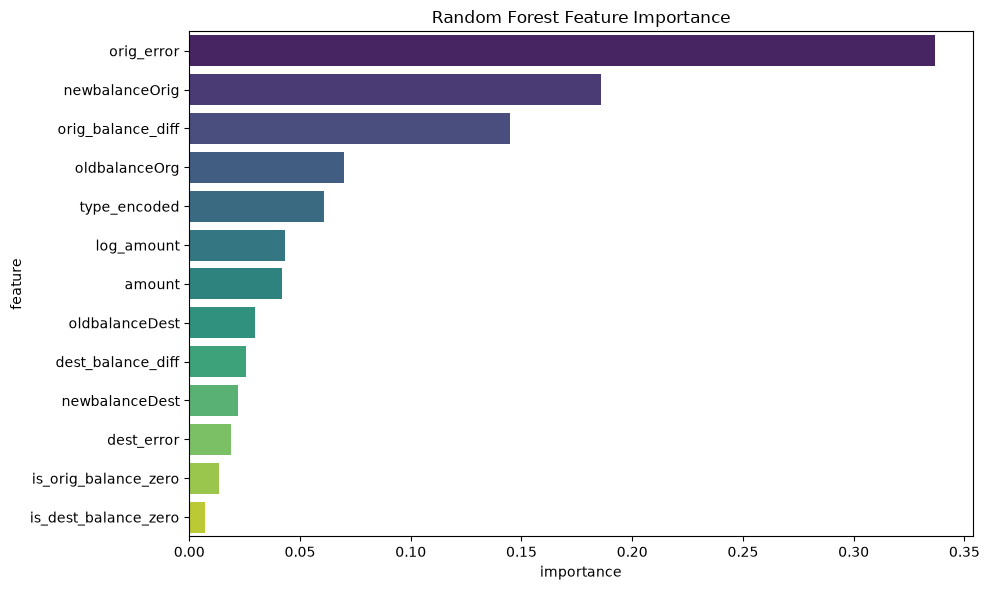

In [8]:
importance = pd.DataFrame({
    'feature': feature_cols,
    'importance': rf.feature_importances_
}).sort_values('importance', ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(data=importance, x='importance', y='feature', palette='viridis')
plt.title('Random Forest Feature Importance')
plt.tight_layout()
plt.show()

In [9]:
import sys
sys.path.append("../src")
from recommendation.rule_based import recommend_action

# Simulate a few transactions
test_cases = [
    {"risk": 0.97, "amount": 120000, "customer_risk": 0.3, "new_device": True,  "unusual_loc": False},
    {"risk": 0.81, "amount": 45000,  "customer_risk": 0.5, "new_device": False, "unusual_loc": True},
    {"risk": 0.35, "amount": 8000,   "customer_risk": 0.1, "new_device": False, "unusual_loc": False},
    {"risk": 0.08, "amount": 1500,   "customer_risk": 0.05,"new_device": False, "unusual_loc": False},
]

for i, case in enumerate(test_cases, 1):
    result = recommend_action(
        risk_score=case["risk"],
        amount=case["amount"],
        customer_risk=case["customer_risk"],
        is_new_device=case["new_device"],
        is_unusual_location=case["unusual_loc"]
    )
    print(f"\n--- Test Case {i} ---")
    print(f"Risk: {case['risk']:.2f} | Amount: ₹{case['amount']:,}")
    print(f"Recommended: {result['recommended_action']} (confidence: {result['confidence']})")
    print(f"Reason: {result['reason']}")
    print("Ranking:", result['all_scores'])


--- Test Case 1 ---
Risk: 0.97 | Amount: ₹120,000
Recommended: BLOCK (confidence: 1.0)
Reason: Very high fraud risk (0.97) | High transaction amount (₹120,000) | New/unrecognized device
Ranking: {'BLOCK': 1.0, 'MANUAL_REVIEW': 0.88, 'STEP_UP_AUTH': 0.2, 'APPROVE': 0.0, 'HOLD': 0.0}

--- Test Case 2 ---
Risk: 0.81 | Amount: ₹45,000
Recommended: MANUAL_REVIEW (confidence: 0.93)
Reason: Elevated fraud risk (0.81) | Unusual location
Ranking: {'MANUAL_REVIEW': 0.93, 'STEP_UP_AUTH': 0.62, 'BLOCK': 0.6, 'APPROVE': 0.0, 'HOLD': 0.0}

--- Test Case 3 ---
Risk: 0.35 | Amount: ₹8,000
Recommended: APPROVE (confidence: 0.55)
Reason: Normal transaction pattern
Ranking: {'APPROVE': 0.55, 'STEP_UP_AUTH': 0.4, 'HOLD': 0.0, 'MANUAL_REVIEW': 0.0, 'BLOCK': 0.0}

--- Test Case 4 ---
Risk: 0.08 | Amount: ₹1,500
Recommended: APPROVE (confidence: 0.9)
Reason: Normal transaction pattern
Ranking: {'APPROVE': 0.9, 'STEP_UP_AUTH': 0.0, 'HOLD': 0.0, 'MANUAL_REVIEW': 0.0, 'BLOCK': 0.0}
